In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
train = pd.read_csv(r"train.csv/train.csv")
test = pd.read_csv(r"test.csv/test.csv")
features = pd.read_csv(r"features.csv/features.csv")

In [3]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [4]:
test.head()

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


In [5]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [6]:
train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])
features['Date'] = pd.to_datetime(test['Date'])

In [7]:
train = pd.merge(train,features, on=['Store', 'Date', 'IsHoliday'], how='left')
test = pd.merge(test, features, on=['Store', 'Date', 'IsHoliday'], how='left')

In [8]:
print(train.shape)
print(train.columns.tolist())

(421570, 14)
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment']


## Sort by Date

In [9]:
train = train.sort_values('Date').reset_index(drop=True)
test = test.sort_values('Date').reset_index(drop=True)

In [10]:
print(train.isnull().sum())

Store                0
Dept                 0
Date                 0
Weekly_Sales         0
IsHoliday            0
Temperature     421570
Fuel_Price      421570
MarkDown1       421570
MarkDown2       421570
MarkDown3       421570
MarkDown4       421570
MarkDown5       421570
CPI             421570
Unemployment    421570
dtype: int64


In [11]:
cols_to_drop = ['Temperature','Fuel_Price','CPI','Unemployment']

train = train.drop(columns=cols_to_drop)
test = test.drop(columns=cols_to_drop)

## Handle Missing Values

In [12]:
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']
train[markdown_cols] = train[markdown_cols].fillna(0)
test[markdown_cols] = test[markdown_cols].fillna(0)

train.ffill()
test.ffill()

print(train.isnull().sum())

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
MarkDown1       0
MarkDown2       0
MarkDown3       0
MarkDown4       0
MarkDown5       0
dtype: int64


## EDA

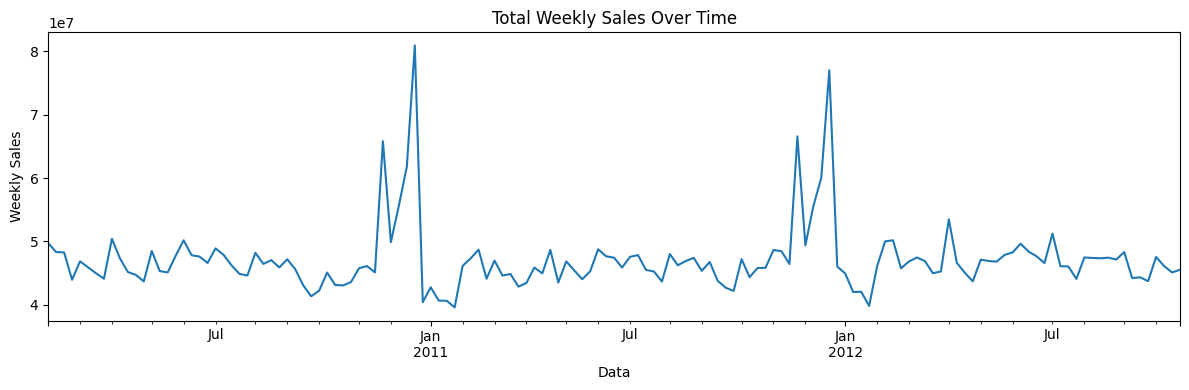

In [13]:
# Weekly sales Trend
train.groupby('Date')['Weekly_Sales'].sum().plot(figsize=(12, 4))
plt.title("Total Weekly Sales Over Time")
plt.xlabel("Data")
plt.ylabel("Weekly Sales")
plt.tight_layout()
plt.show()

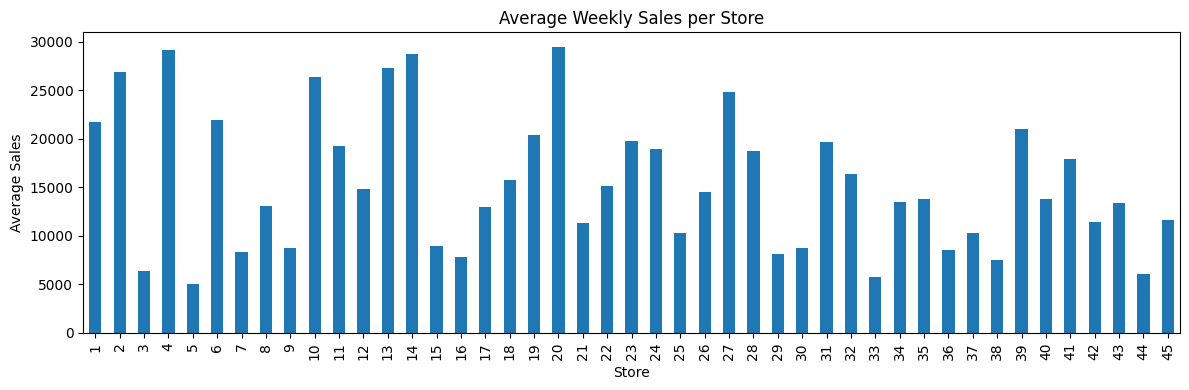

In [14]:
# Average sales per store
train.groupby('Store')['Weekly_Sales'].mean().plot(kind='bar', figsize=(12, 4))
plt.title("Average Weekly Sales per Store")
plt.xlabel("Store")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

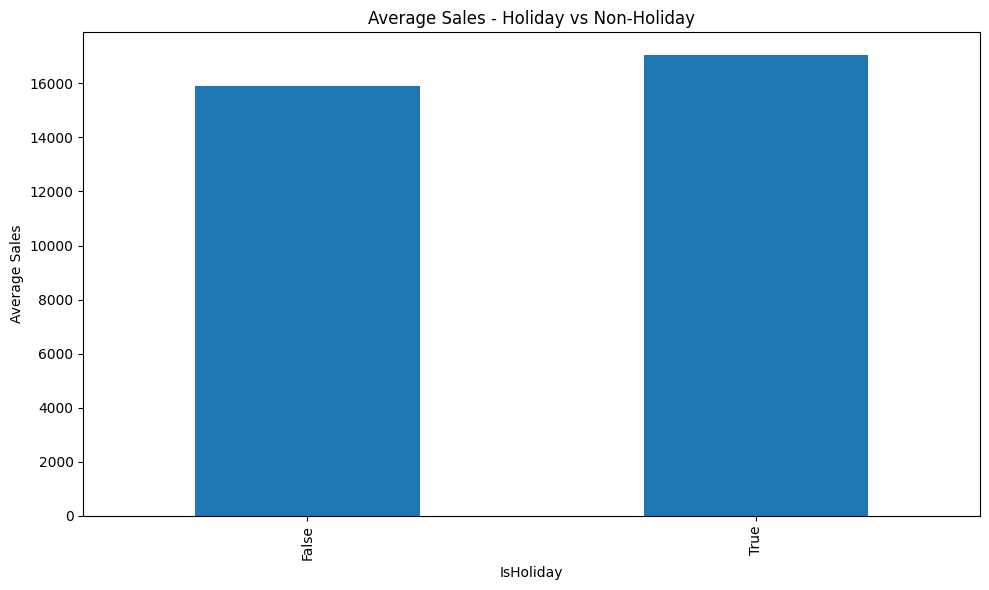

In [15]:
# Holiday vs Non-Holiday sales
train.groupby('IsHoliday')['Weekly_Sales'].mean().plot(kind='bar', figsize=(10, 6))
plt.title("Average Sales - Holiday vs Non-Holiday")
plt.xlabel("IsHoliday")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

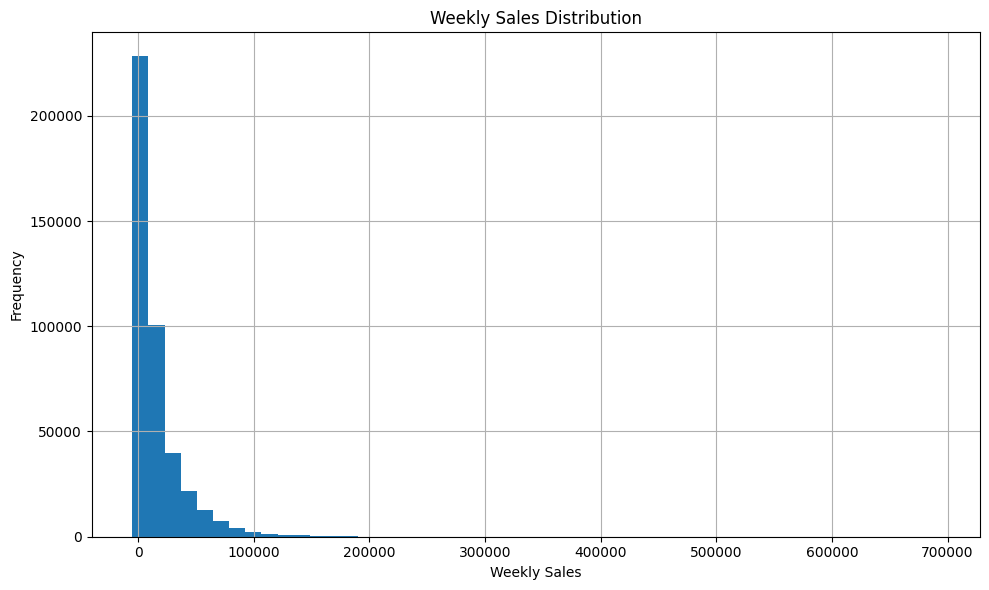

In [16]:
# Sales distribution
train['Weekly_Sales'].hist(bins=50, figsize=(10, 6))
plt.title("Weekly Sales Distribution")
plt.xlabel("Weekly Sales")
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## Filter One Store & Department

In [17]:
df = train[(train['Store']== 1) & (train['Dept'] == 1)].copy()
df = df.set_index("Date")
df = df.sort_index()
df = df.asfreq("W-FRI")   # Weekly Frequenct ending Friday

series = df['Weekly_Sales']
print(series.shape)
print(series.head())

(143,)
Date
2010-02-05    24924.50
2010-02-12    46039.49
2010-02-19    41595.55
2010-02-26    19403.54
2010-03-05    21827.90
Freq: W-FRI, Name: Weekly_Sales, dtype: float64


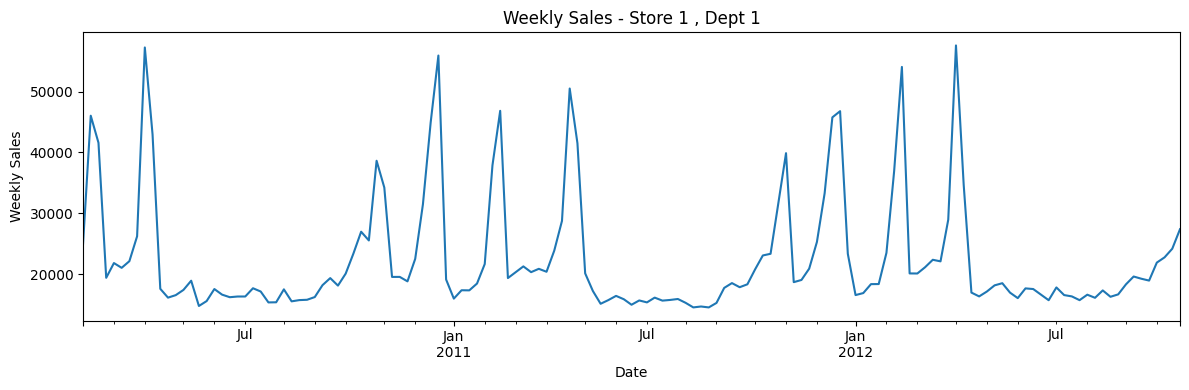

In [18]:
series.plot(figsize=(12, 4))
plt.title("Weekly Sales - Store 1 , Dept 1")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.tight_layout()
plt.show()

In [19]:
print(f"Missing values : {series.isnull().sum()}")
series = series.ffill()

Missing values : 0


## Check Stationarity - ADF test

In [20]:
result = adfuller(series)
print(f"ADF Statistic : {result[0]:.4f}")
print(f"p-value : {result[1]:.4f}")

if result[1] < 0.05:
    print("Series is Stationary")
else:
    print('Series is not Stationary')

ADF Statistic : -2.5222
p-value : 0.1102
Series is not Stationary


After differencing p_value : 0.000000


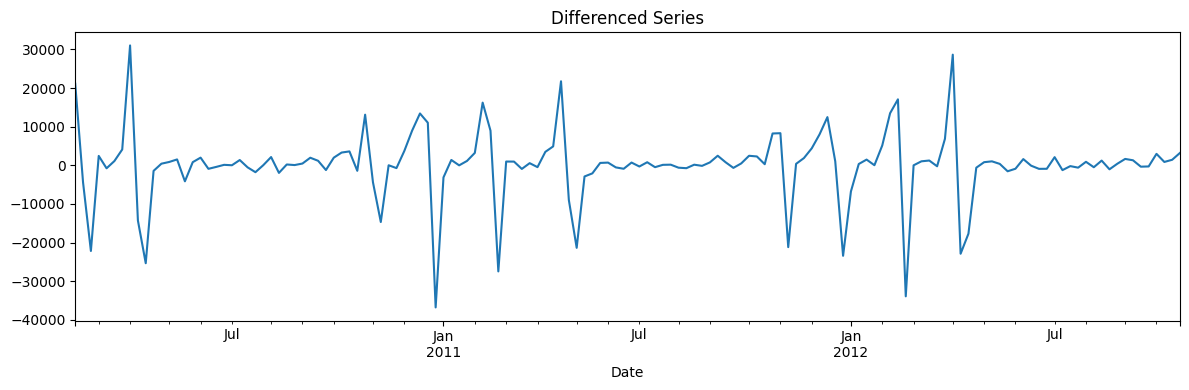

In [21]:
series_diff = series.diff().dropna()

# re-check stationarity
result2 = adfuller(series_diff)
print(f"After differencing p_value : {result2[1]:4f}")
if result2[1] > 0.05:
    print("Series is now stationary")

series_diff.plot(figsize=(12,4))
plt.title("Differenced Series")
plt.tight_layout()
plt.show()

## ACF & PACF plots

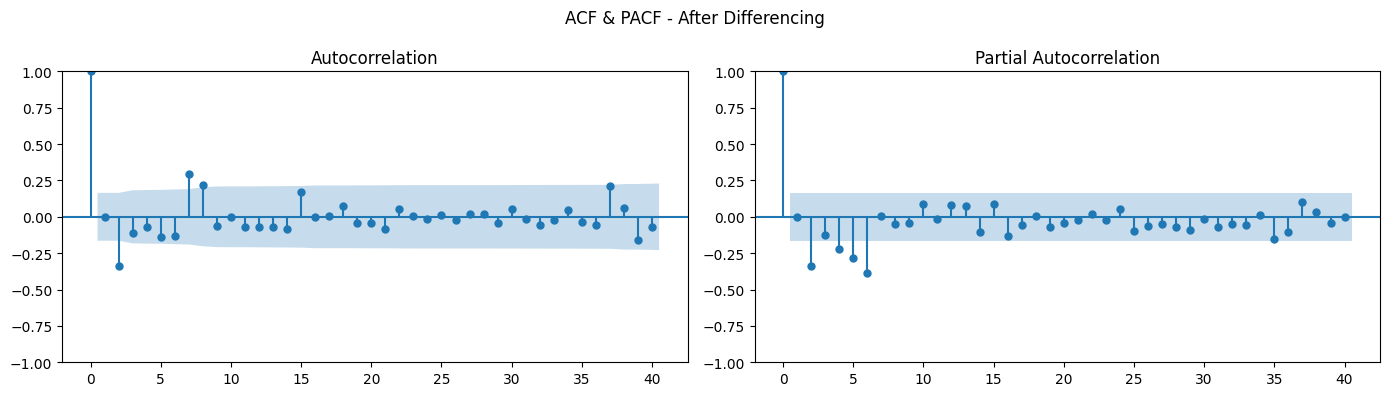

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(series_diff, ax=axes[0], lags=40)
plot_pacf(series_diff, ax=axes[1], lags=40)
plt.suptitle("ACF & PACF - After Differencing")
plt.tight_layout()
plt.show()

In [23]:
split = int(len(series) * 0.8)
train_s = series[:split]
test_s = series[split:]

print(f"Train size: {len(train_s)}")
print(f"Test size: {len(test_s)}")

Train size: 114
Test size: 29


## ARIMA Model

ARIMA MAE: 6642.22
ARIMA RMSE : 7474.89


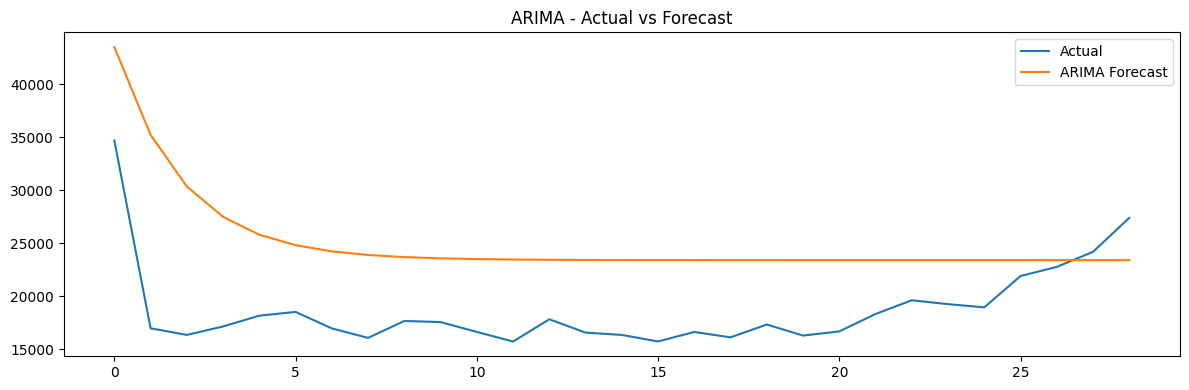

In [24]:
arima_model = ARIMA(train_s, order=(1,1,1))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test_s))

arima_mae = mean_absolute_error(test_s, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test_s, arima_forecast))
print(f'ARIMA MAE: {arima_mae:.2f}')
print(f"ARIMA RMSE : {arima_rmse:.2f}")

plt.figure(figsize=(12, 4))
plt.plot(test_s.values, label='Actual')
plt.plot(arima_forecast.values, label='ARIMA Forecast')
plt.title('ARIMA - Actual vs Forecast')
plt.legend()
plt.tight_layout()
plt.show()


## SARIMA Model

In [25]:
sarima_model = SARIMAX(train_s, 
                      order = (1,1 ,1),
                      seasonal_order=(1,1,1,52))
sarima_fit = sarima_model.fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=len(test_s))

sarima_mae = mean_absolute_error(test_s, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test_s, sarima_forecast))
print(f"SARIMA MAE : {sarima_mae:.2f}")
print(f"SARIMA RMSE: {sarima_rmse:.2f}")

C:\Users\Akshay12\anaconda3\envs\mynotebook\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


SARIMA MAE : 10768.75
SARIMA RMSE: 12259.56


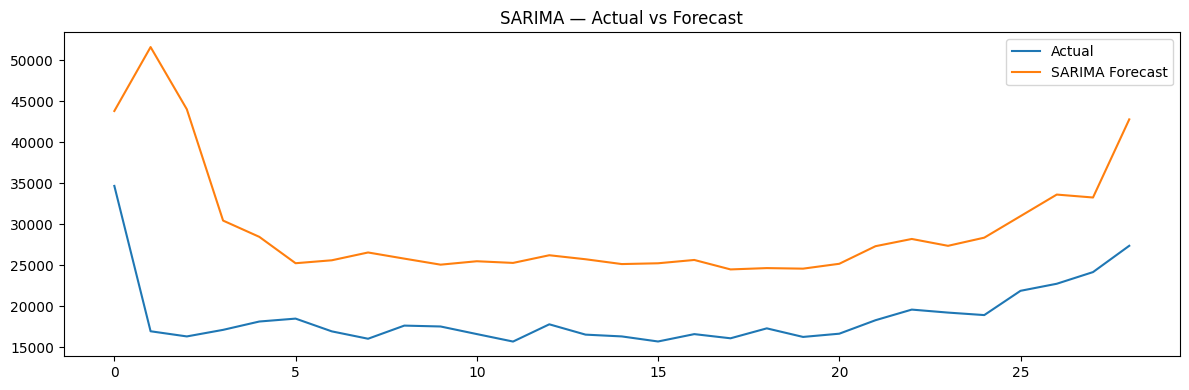

In [26]:
plt.figure(figsize=(12, 4))
plt.plot(test_s.values,          label='Actual')
plt.plot(sarima_forecast.values, label='SARIMA Forecast')
plt.title("SARIMA — Actual vs Forecast")
plt.legend()
plt.tight_layout()
plt.show()

## Exponential Smoothing Model

In [27]:
es_model = ExponentialSmoothing(train_s, 
                               trend='add',
                               seasonal='add',
                               seasonal_periods=52)

es_fit = es_model.fit()
es_forecast = es_fit.forecast(steps=len(test_s))

es_mae = mean_absolute_error(test_s, es_forecast)
es_rmse = np.sqrt(mean_squared_error(test_s, es_forecast))
print(f"Exp Smoothing MAE: {es_mae:.2f}")
print(f"Exp Smoothing RMSE: {es_rmse:.2f}")

Exp Smoothing MAE: 62364.34
Exp Smoothing RMSE: 64912.64


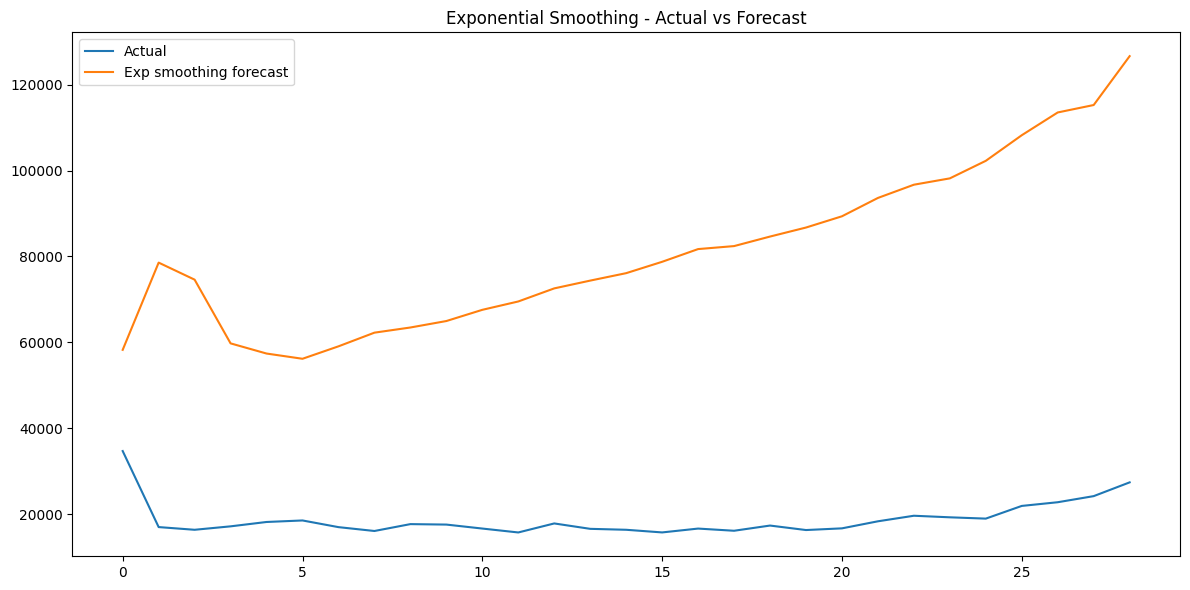

In [28]:
plt.figure(figsize=(12, 6))
plt.plot(test_s.values,     label='Actual')
plt.plot(es_forecast.values, label='Exp smoothing forecast')
plt.title("Exponential Smoothing - Actual vs Forecast")
plt.legend()
plt.tight_layout()
plt.show()

## Model comparison

In [29]:
results = pd.DataFrame({
    'Model': ['ARIMA', 'SARIMA', 'Exponential Smoothing'],
    'MAE': [arima_mae, sarima_mae, es_mae],
    'RMSE': [arima_rmse, sarima_rmse, es_rmse]
})
print(results)

                   Model           MAE          RMSE
0                  ARIMA   6642.217777   7474.885983
1                 SARIMA  10768.748832  12259.559880
2  Exponential Smoothing  62364.338219  64912.636050


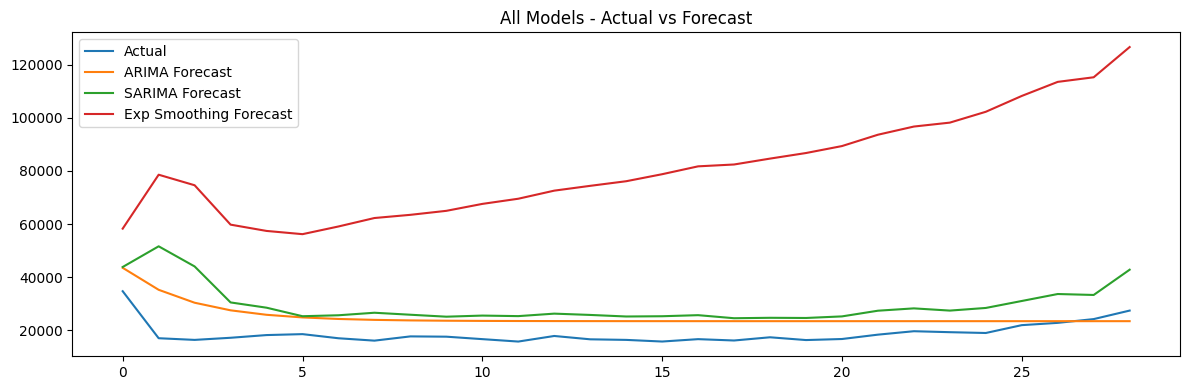

In [30]:
plt.figure(figsize=(12, 4))
plt.plot(test_s.values, label="Actual")
plt.plot(arima_forecast.values, label='ARIMA Forecast')
plt.plot(sarima_forecast.values, label='SARIMA Forecast')
plt.plot(es_forecast.values, label='Exp Smoothing Forecast')
plt.title("All Models - Actual vs Forecast")
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
from pmdarima import auto_arima

model = auto_arima(train_s,
                  start_p=0, max_p=5,      # AR search range
                  start_q=0, max_q=5,      # MA search range
                  d=None, max_d=2,
                   seasonal=True, m=12,
                   information_criterion='aic',
                   stepwise=True,          # fast search
                   trace=True,
                   supress_warnings=True,
                   error_action='ignore'
                  )
model.summary()

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(1,0,1)[12] intercept   : AIC=2437.902, Time=0.22 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=2440.783, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=2404.095, Time=0.24 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=2396.695, Time=0.06 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=2641.120, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : AIC=2396.824, Time=0.04 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : AIC=2397.678, Time=0.29 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : AIC=2397.736, Time=0.15 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : AIC=2398.758, Time=0.11 sec
 ARIMA(0,0,1)(1,0,2)[12] intercept   : AIC=2398.794, Time=0.66 sec
 ARIMA(0,0,0)(0,0,1)[12] intercept   : AIC=2436.108, Time=0.05 sec
 ARIMA(1,0,1)(0,0,1)[12] intercept   : AIC=2396.976, Time=0.11 sec
 ARIMA(0,0,2)(0,0,1)[12] intercept   : AIC=2395.577, Time=0.11 sec
 ARIMA(0,0,2)(0,0,0)[12] intercept   : AIC=2394.973, Time=0.05 sec
 ARIMA(0,0,2)(1,0,0

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  114
Model:               SARIMAX(0, 0, 2)   Log Likelihood               -1193.487
Date:                Thu, 12 Mar 2026   AIC                           2394.973
Time:                        15:12:26   BIC                           2405.918
Sample:                    02-05-2010   HQIC                          2399.415
                         - 04-06-2012                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   2.251e+04   2232.511     10.084      0.000    1.81e+04    2.69e+04
ma.L1          0.7680      0.110      6.987      0.000       0.553       0.983
ma.L2          0.1815      0.120      1.516      0.130      -0.053       0.416
sigma2      7.773e+07      0.458    1.7e+08      0.000    7.77e+07    7.77e+07
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                64.57
Prob(Q):                              0.95   Prob(JB):                         0.00
Heteroskedasticity (H):               1.68   Skew:                             1.17
Prob(H) (two-sided):                  0.12   Kurtosis:                         5.85
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 2.47e+25. Standard errors may be unstable.
"""